<a href="https://colab.research.google.com/github/cincysam6/UC_Causal_Inf_2026/blob/main/eda_itt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA: Randomized Holdout (ITT) Dataset
### Exploring Household Characteristics and Verifying Randomization

---

## How to Use This Notebook

This is the **second notebook** in the lab sequence. After seeing how selection bias distorts the observational data (notebook 1), we now examine the randomized holdout dataset — where households were assigned to treatment and control *at random*.

Work through each section in order. Each section begins with a **Step** header explaining what you are about to do and why. After each key result, a **What This Means** section explains how to interpret the output.

---

## Background

In a **randomized holdout experiment**, a sample of eligible households is withheld from receiving advertising (the "holdout" or control group). The remaining households are exposed to the campaign as normal. Because the assignment to holdout or treatment is random, the two groups are expected to look similar on all characteristics — including ones we cannot measure.

**Key questions we will explore:**
- What does the data look like?
- Did randomization produce balanced groups? (This is the crucial check)
- Is there any sign of imperfect randomization?
- How does the outcome compare to the observational dataset?
- What relationships exist between pre-period variables and the outcome?

**Why this is different from the observational dataset:** In the observational data, who received ads depended on targeting decisions. Here, it depends only on a random number — making the two groups directly comparable.

---
## Step 1: Setup — Load Libraries and Data

**What we are doing:** Import libraries and load the ITT (Intent-to-Treat) dataset — the randomized holdout experiment data.

**What to look for after running this cell:**
- How many total households are in the experiment?
- What fraction were assigned to treatment vs. control?
- A 70/30 or 80/20 split is common in advertising holdout tests — a smaller holdout allows more treated customers to see ads while still providing a valid comparison group

In [35]:
pip install seaborn

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats

# ── Color palette ─────────────────────────────────────────────────────────────
TREATED_COLOR = '#E07B54'   # orange-red for treated group
CONTROL_COLOR = '#5B8DB8'   # steel blue for control group
FLAG_COLOR    = '#C0392B'   # red for flagging the geographic anomaly in div_code 508

# ── Global plot style ─────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

# ── Load the randomized holdout dataset ───────────────────────────────────────
# Updated path to point to your mounted Google Drive under 'UC_CI'
try:
    df = pd.read_csv('/content/drive/MyDrive/itt_dataset.csv')
except FileNotFoundError:
    try:
        df = pd.read_csv('/content/drive/MyDrive/UC_CI/data/itt_dataset.csv')
    except FileNotFoundError:
        print("Could not find 'itt_dataset.csv' in the root of your Google Drive or 'UC_CI' folder.")
        print("Please upload 'itt_dataset.csv' to your 'UC_CI' folder on Google Drive and run this cell again.")
        raise

# Split into treatment and control for easy access throughout the notebook
treated = df[df['is_treated'] == 1]
control = df[df['is_treated'] == 0]

print(f'Rows: {len(df):,}')
print(f'Treated: {len(treated):,}  ({len(treated)/len(df):.1%})')
print(f'Control: {len(control):,}  ({len(control)/len(df):.1%})')

Rows: 50,000
Treated: 35,594  (71.2%)
Control: 14,406  (28.8%)


In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Step 2: Dataset Snapshot

**What we are doing:** Preview the first rows of the data and compute summary statistics.

**What to compare to the observational dataset:** The variable names are identical — same household-level features, same outcome. The only structural difference is that `is_treated` here was assigned randomly rather than through a targeting algorithm.

**Key thing to notice:** The `describe()` output should show similar statistics to the observational dataset — because both datasets were drawn from the same population. Any differences between treated and control in this dataset should be due to chance, not targeting.

In [38]:
df.head(10)

,hh_id,hh_size,div_code,ecomm_loyalty,price_sensitivity,pre_52_category_spend,pre_52_brand_buyer,pre_52_brand_spend,pre_52_store_spend,pre_52_store_visits,pre_52_brand_visits,is_treated,post_brand_sales
0,1,3,101,high,medium,10.369124,1,2.974076,255.727945,31,7,1,0.662103
1,2,3,204,medium,low,22.393271,1,5.804968,113.433609,28,10,1,0.523594
2,3,2,923,medium,medium,34.962911,0,0.000000,158.934307,30,9,1,0.848914
3,4,1,508,low,low,11.309249,0,0.000000,98.055503,21,3,1,0.211551
4,5,4,923,medium,high,28.437499,1,7.290108,64.800485,25,7,1,1.118222
5,6,4,612,medium,medium,10.309980,0,0.000000,29.644675,32,6,0,0.747846
6,7,3,612,medium,high,40.661636,1,9.039245,293.546035,18,7,0,1.211781
7,8,2,204,high,low,23.481003,0,0.000000,46.058476,44,8,1,0.880376
8,9,2,508,high,medium,23.014483,1,3.386465,144.838175,27,10,1,0.772499
9,10,3,715,high,medium,5.434346,0,0.000000,227.935224,29,5,0,0.398723


In [39]:
df.describe().round(3)

,hh_id,hh_size,div_code,pre_52_category_spend,pre_52_brand_buyer,pre_52_brand_spend,pre_52_store_spend,pre_52_store_visits,pre_52_brand_visits,is_treated,post_brand_sales
count,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000,50000.000
mean,25000.500,3.101,466.721,16.784,0.452,1.546,115.136,25.990,6.503,0.712,0.663
std,14433.901,1.300,288.880,15.802,0.498,2.933,91.910,5.096,2.532,0.453,0.255
min,1.000,1.000,37.000,0.441,0.000,0.000,5.094,8.000,0.000,0.000,0.000
25%,12500.750,2.000,204.000,7.173,0.000,0.000,56.274,22.000,5.000,0.000,0.495
50%,25000.500,3.000,423.000,12.183,0.000,0.000,90.090,26.000,6.000,1.000,0.649
75%,37500.250,4.000,715.000,20.925,1.000,2.111,143.671,29.000,8.000,1.000,0.812
max,50000.000,6.000,923.000,383.835,1.000,60.505,1669.098,50.000,23.000,1.000,3.613


---
## Step 3: Distributions of Key Variables — Comparing Treated and Control

**What we are doing:** Plot spending distributions separately for treated and control households on the same axes.

**The key test:** In the observational dataset, treated households had clearly higher spending distributions — because high-spend households were preferentially targeted. In a randomized experiment, the distributions for treated and control should **overlap almost perfectly** — because treatment assignment was random and independent of spending.

**What to look for:**
- Do the treated (orange) and control (blue) distributions sit on top of each other?
- Are the means (marked by dashed lines) similar between groups?
- If the distributions look different for pre-campaign variables, randomization may have failed

**Note on the post-campaign outcome:** Even in the ITT dataset, we expect a slight separation in `post_brand_sales` between treated and control — because advertising has a real (though small) effect. This separation should be much smaller than in the observational data.

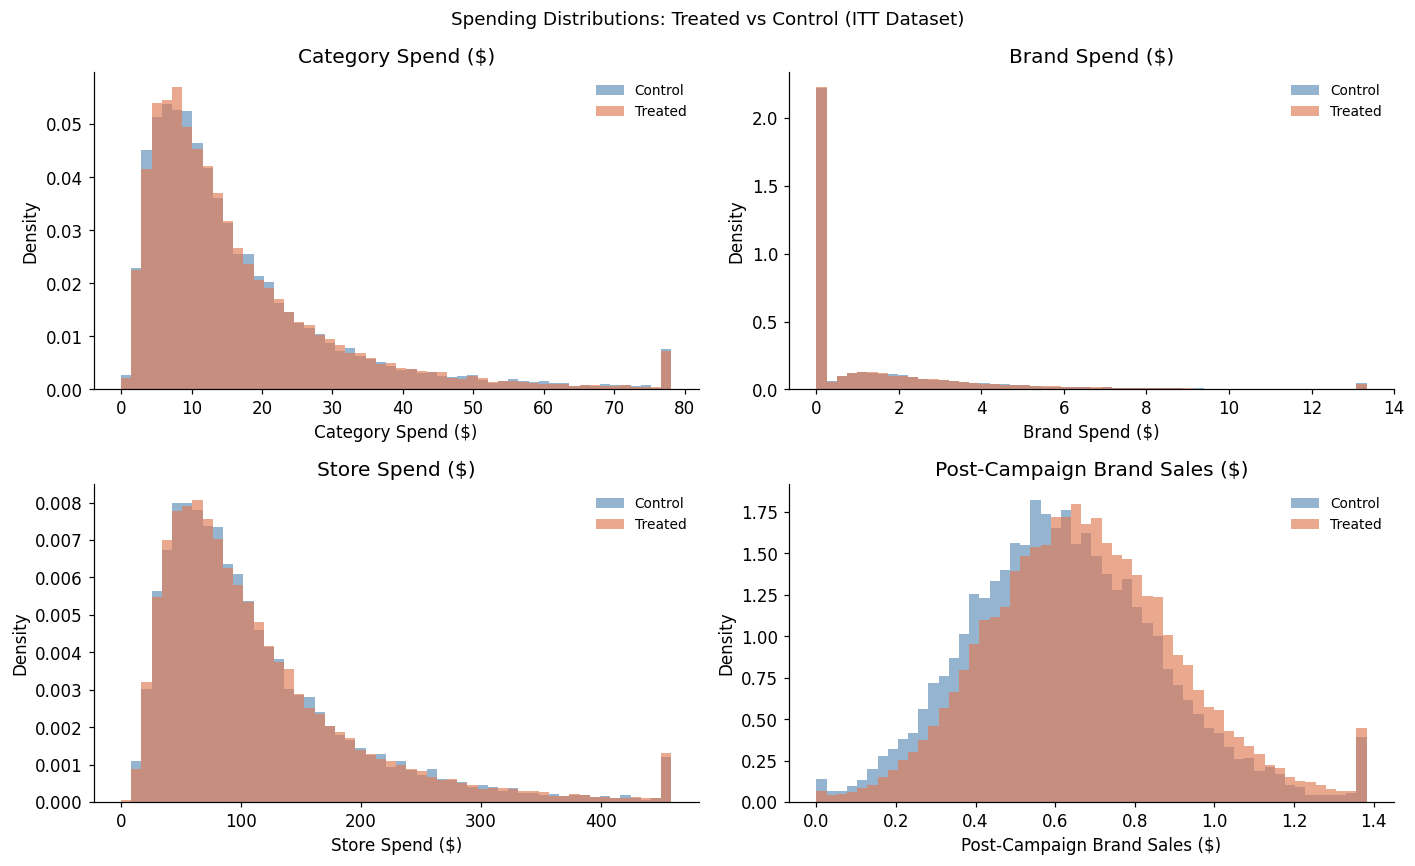

In a well-randomized dataset, treated and control distributions should overlap closely.
Compare this to the observational dataset where treated households clearly spend more.


In [40]:
# ── Spending distributions by treatment group ─────────────────────────────────
spend_vars = [
    ('pre_52_category_spend', 'Category Spend ($)'),
    ('pre_52_brand_spend',    'Brand Spend ($)'),
    ('pre_52_store_spend',    'Store Spend ($)'),
    ('post_brand_sales',      'Post-Campaign Brand Sales ($)'),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, (col, label) in zip(axes.flat, spend_vars):
    cap = df[col].quantile(0.99)
    bins = np.linspace(0, cap, 55)
    ax.hist(control[col].clip(upper=cap), bins=bins, alpha=0.65,
            color=CONTROL_COLOR, label='Control', density=True)
    ax.hist(treated[col].clip(upper=cap), bins=bins, alpha=0.65,
            color=TREATED_COLOR, label='Treated', density=True)
    ax.set_xlabel(label)
    ax.set_ylabel('Density')
    ax.set_title(label)
    ax.legend(fontsize=9, frameon=False)

plt.suptitle('Spending Distributions: Treated vs Control (ITT Dataset)', fontsize=12)
plt.tight_layout()
plt.show()

print('In a well-randomized dataset, treated and control distributions should overlap closely.')
print('Compare this to the observational dataset where treated households clearly spend more.')

---
## Step 4: Balance Check — Did Randomization Work?

**What we are doing:** Formally test whether treated and control households look similar on all pre-campaign characteristics. This is the single most important diagnostic for any randomized experiment.

**Why a balance check matters:** Even with random assignment, balance is not guaranteed by construction for any given sample. We want to verify empirically that, in this particular dataset, the two groups are similar.

**The standardized difference** is the key metric here — not the p-value. The standardized difference is:

$$\text{Std Diff} = \frac{\bar{X}_{\text{treated}} - \bar{X}_{\text{control}}}{\sqrt{(s_T^2 + s_C^2)/2}}$$

It measures the size of the difference relative to the variability of the variable. A value below 0.10 in absolute terms is considered negligible imbalance.

**Important warning about p-values:** With a large sample (50,000 households), a t-test will produce p-values below 0.05 for even very tiny differences. A statistically significant p-value does NOT mean the imbalance is practically important. Focus on standardized differences.

**What to look for:**
- Are all standardized differences below 0.10?
- Is there any variable where treated and control look noticeably different?
- If a variable shows |Std Diff| > 0.20, investigate why

---
## 3. Balance Check: Did Randomization Work?

The single most important check for a randomized experiment is whether the groups look similar on pre-treatment characteristics. **We should not see systematic differences** on variables measured before the campaign.

In [41]:
# ── Numeric balance table ─────────────────────────────────────────────────────
numeric_vars = [
    'pre_52_category_spend',
    'pre_52_brand_buyer',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'pre_52_brand_visits',
    'hh_size',
]

rows = []
for var in numeric_vars:
    t_vals = treated[var]
    c_vals = control[var]
    diff   = t_vals.mean() - c_vals.mean()
    pooled_sd = np.sqrt((t_vals.var() + c_vals.var()) / 2)
    std_diff  = diff / pooled_sd if pooled_sd > 0 else 0
    _, p_val  = stats.ttest_ind(t_vals, c_vals)
    rows.append({
        'Variable': var,
        'Treated Mean': round(t_vals.mean(), 3),
        'Control Mean': round(c_vals.mean(), 3),
        'Std Diff': round(std_diff, 3),
        'p-value': round(p_val, 3),
    })

balance = pd.DataFrame(rows)
print('Balance Table: ITT Dataset')
print('=' * 65)
print(balance.to_string(index=False))
print()
print('|Std Diff| < 0.10 → negligible imbalance (rule of thumb)')
print()
max_imbalance = balance['Std Diff'].abs().max()
print(f'Largest imbalance: {max_imbalance:.3f}')
if max_imbalance < 0.10:
    print('✓ All variables well-balanced. Randomization appears to have worked on these variables.')
else:
    print('! Some imbalance detected — investigate further.')

Balance Table: ITT Dataset
             Variable  Treated Mean  Control Mean  Std Diff  p-value
pre_52_category_spend        16.761        16.840    -0.005    0.611
   pre_52_brand_buyer         0.451         0.454    -0.005    0.583
   pre_52_brand_spend         1.542         1.556    -0.005    0.643
   pre_52_store_spend       115.160       115.076     0.001    0.926
  pre_52_store_visits        26.000        25.965     0.007    0.494
  pre_52_brand_visits         6.498         6.517    -0.007    0.453
              hh_size         3.099         3.107    -0.007    0.503

|Std Diff| < 0.10 → negligible imbalance (rule of thumb)

Largest imbalance: 0.007
✓ All variables well-balanced. Randomization appears to have worked on these variables.


---
## Step 5: Geographic Check — Is Treatment Randomly Distributed Across Divisions?

**What we are doing:** Examine whether the treatment rate (proportion of households assigned to advertising) is consistent across all geographic divisions (`div_code`).

**Why this check is important:** Randomization is typically done at the household level, but the *deployment* of a campaign often happens at a geographic level (stores, regions, markets). If one division received a different treatment rate than intended — due to implementation error, a delayed launch, or different coverage — we can end up with geographic imbalance even when household-level randomization was correct.

**What to look for:**
- Is the treatment rate approximately the same across all divisions?
- Does any division stand out as having a notably higher or lower treatment rate?
- If a division has an unusual rate: is that division also unusual in its household characteristics? (That would be a more serious concern)

**The answer to find:** One division in this dataset has a noticeably higher treatment rate than the others. This is a deliberate feature of the synthetic data to illustrate a real-world issue that analysts frequently encounter in market-level experiments.

In [42]:
# ── Categorical balance: ecomm_loyalty and price_sensitivity ──────────────────
for var in ['ecomm_loyalty', 'price_sensitivity']:
    t_dist = treated[var].value_counts(normalize=True).sort_index()
    c_dist = control[var].value_counts(normalize=True).sort_index()
    cat_tbl = pd.DataFrame({'Treated': t_dist, 'Control': c_dist})
    cat_tbl['Diff (pp)'] = ((cat_tbl['Treated'] - cat_tbl['Control']) * 100).round(2)
    print(f'\n{var}:')
    print(cat_tbl.to_string())


ecomm_loyalty:
                Treated   Control  Diff (pp)
ecomm_loyalty                               
high           0.201888  0.199847       0.20
low            0.304124  0.300222       0.39
medium         0.493988  0.499931      -0.59

price_sensitivity:
                    Treated   Control  Diff (pp)
price_sensitivity                               
high               0.246193  0.248855      -0.27
low                0.305023  0.295294       0.97
medium             0.448784  0.455852      -0.71


---
## 4. Geographic Check: Treatment Rate by Division

Even when randomization is correct at the household level, implementation issues can cause **geographic imbalance** — some regions may have a higher or lower treatment probability than intended.

This is a common real-world issue in advertising experiments, especially when campaigns are deployed region by region.

---
## Step 6: Outcome Variable — How Large Is the Post-Campaign Difference?

**What we are doing:** Compare post-campaign brand sales between randomly assigned treated and control households. This simple difference is the **naive ITT estimate** — and because randomization worked, it is also approximately an **unbiased causal estimate**.

**The fundamental contrast with the observational data:** In the observational dataset, the treated-control gap was driven partly by advertising and partly by pre-existing differences. Here, with randomization, the pre-existing differences are balanced out — so the observed gap more directly reflects the causal effect of advertising.

**Key number to keep in mind:** The true ATE in this synthetic dataset is **$0.05** (an 8% lift over the control mean). The ITT estimate should be close to this value.

**What to look for:**
- How similar are the treated and control distribution shapes?
- What is the naive ATE? Is it close to $0.05?
- Compare the naive ATE here to the ~$0.11 from the observational dataset — the difference is almost entirely selection bias

In [43]:
# ── Treatment rate by division ────────────────────────────────────────────────
div_stats = (
    df.groupby('div_code')
    .agg(n=('hh_id','count'), treat_rate=('is_treated','mean'))
    .reset_index()
    .sort_values('treat_rate', ascending=False)
)
overall_rate = df['is_treated'].mean()

print(f'Overall treatment rate: {overall_rate:.1%}')
print()
print('Treatment rate by division:')
div_stats['treat_rate_pct'] = (div_stats['treat_rate']*100).round(1)
print(div_stats[['div_code','n','treat_rate_pct']].to_string(index=False))

Overall treatment rate: 71.2%

Treatment rate by division:
 div_code    n  treat_rate_pct
      508 4922            81.9
      923 5176            70.5
      423 5021            70.4
      317 5038            70.3
      612 4917            70.2
       37 5032            70.2
      101 4979            69.8
      819 4947            69.7
      715 4998            69.6
      204 4970            69.4


---
## Step 7: Feature–Outcome Relationships in the Randomized Data

**What we are doing:** Explore how pre-campaign variables relate to the post-campaign outcome within each treatment group.

**Why this analysis is different from the observational version:** In the observational data, a higher-spend household was both more likely to be treated AND more likely to have higher post-campaign sales. Those two facts were confounded. In the ITT data, treatment is random — so we can separately study:
1. How pre-period behavior predicts outcomes (a relationship that exists regardless of advertising)
2. Whether the treatment effect varies across segments (heterogeneous treatment effects)

**What to look for:**
- Is the treatment-control gap (lift) similar across spending quintiles, or does it vary?
- Do high-loyalty households have higher baseline sales? (They should — but so does control group in those segments)
- Is there evidence of treatment effect heterogeneity — some segments benefiting more from advertising than others?

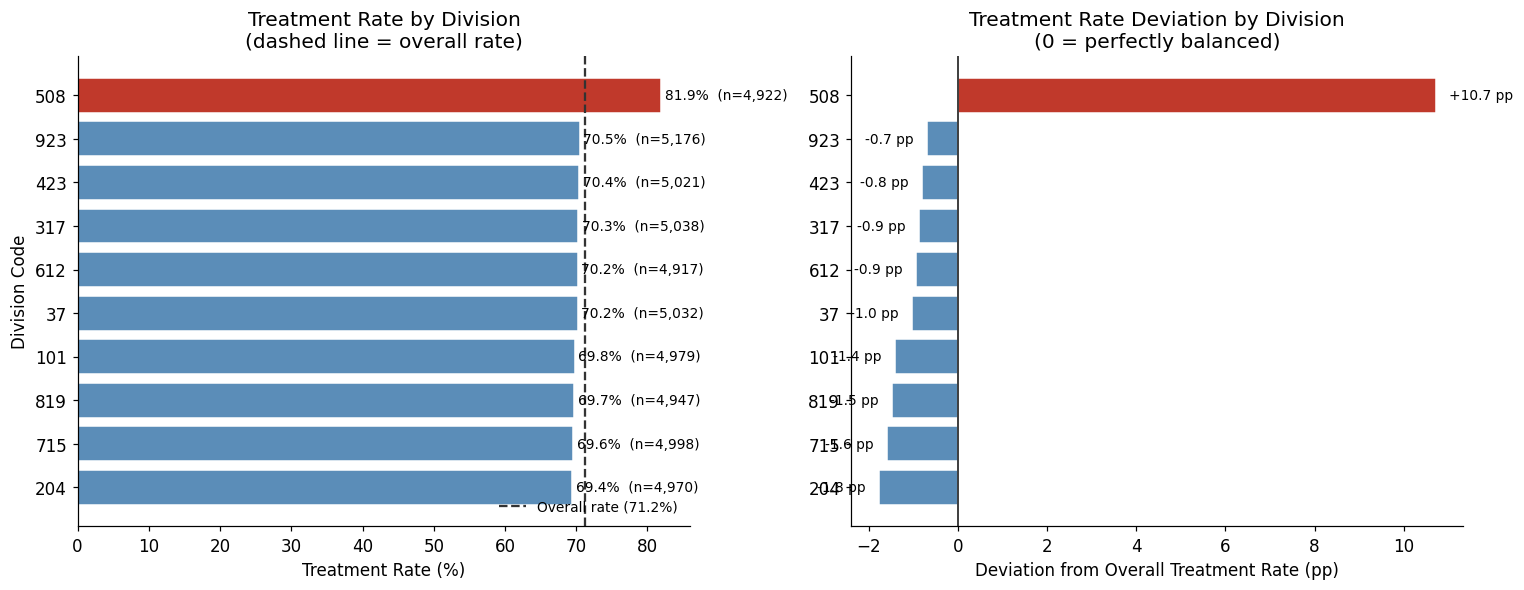

Division 508 treatment rate:     81.9%   (overall: 71.2%)
All other divisions (avg):       70.0%
Treatment rate elevation:        +11.9 pp above other divisions

Division 508 size:               4,922 households  (9.8% of dataset)
Treated in Div 508:              4,031   Control: 891

Range of treatment rates:        69.4% – 81.9%
Std dev of division rates:       3.78 pp

⚠ Division 508 is a clear outlier — its treatment rate is noticeably
  higher than every other division, suggesting a geographic implementation
  issue rather than random chance. This is the kind of subtle imbalance
  that can go unnoticed without geographic stratification checks.


In [44]:
# ── Geographic Imbalance: Visualizing the Treatment Rate Skew ─────────────────

# Compute per-division stats
div_detail = (
    df.groupby('div_code')
    .agg(n=('hh_id', 'count'), treat_rate=('is_treated', 'mean'))
    .reset_index()
)
div_detail['treat_rate_pct'] = (div_detail['treat_rate'] * 100).round(1)
div_detail['rate_dev'] = (div_detail['treat_rate'] - overall_rate) * 100
div_detail['n_treated'] = df.groupby('div_code')['is_treated'].sum().values.astype(int)
div_detail['n_control'] = div_detail['n'] - div_detail['n_treated']

# ── Figure with two panels ────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel 1: Treatment rate by division (absolute) with overall reference ---
div_sorted = div_detail.sort_values('treat_rate')
bar_colors = [FLAG_COLOR if c == 508 else CONTROL_COLOR for c in div_sorted['div_code']]

ax1.barh(
    div_sorted['div_code'].astype(str),
    div_sorted['treat_rate_pct'],
    color=bar_colors, edgecolor='white'
)
ax1.axvline(overall_rate * 100, color='#333333', linewidth=1.5, linestyle='--',
            label=f'Overall rate ({overall_rate:.1%})')
for i, (rate, code, n) in enumerate(
    zip(div_sorted['treat_rate_pct'], div_sorted['div_code'], div_sorted['n'])
):
    ax1.text(rate + 0.5, i, f'{rate:.1f}%  (n={n:,})', va='center', fontsize=9)
ax1.set_xlabel('Treatment Rate (%)')
ax1.set_ylabel('Division Code')
ax1.set_title('Treatment Rate by Division\n(dashed line = overall rate)')
ax1.legend(frameon=False, fontsize=9, loc='lower right')

# --- Panel 2: Deviation from overall rate (highlights the imbalance) ---
div_sorted2 = div_detail.sort_values('rate_dev')
bar_colors2 = [FLAG_COLOR if c == 508 else CONTROL_COLOR for c in div_sorted2['div_code']]

ax2.barh(
    div_sorted2['div_code'].astype(str),
    div_sorted2['rate_dev'],
    color=bar_colors2, edgecolor='white'
)
ax2.axvline(0, color='#333333', linewidth=1.2, linestyle='-')
for i, (dev, code) in enumerate(zip(div_sorted2['rate_dev'], div_sorted2['div_code'])):
    offset = 0.3 if dev >= 0 else -0.3
    ha = 'left' if dev >= 0 else 'right'
    ax2.text(dev + offset, i, f'{dev:+.1f} pp', va='center', ha=ha, fontsize=9)
ax2.set_xlabel('Deviation from Overall Treatment Rate (pp)')
ax2.set_ylabel('')
ax2.set_title('Treatment Rate Deviation by Division\n(0 = perfectly balanced)')

plt.tight_layout()
plt.show()

# ── Summary statistics ────────────────────────────────────────────────────────
div_508 = div_detail[div_detail['div_code'] == 508].iloc[0]
others  = div_detail[div_detail['div_code'] != 508]
rate_508    = div_508['treat_rate']
rate_others = others['treat_rate'].mean()
n_508       = int(div_508['n'])
share_508   = n_508 / len(df)

print(f'Division 508 treatment rate:     {rate_508:.1%}   (overall: {overall_rate:.1%})')
print(f'All other divisions (avg):       {rate_others:.1%}')
print(f'Treatment rate elevation:        {(rate_508 - rate_others)*100:+.1f} pp above other divisions')
print()
print(f'Division 508 size:               {n_508:,} households  ({share_508:.1%} of dataset)')
print(f'Treated in Div 508:              {int(div_508["n_treated"]):,}   Control: {int(div_508["n_control"]):,}')
print()
print(f'Range of treatment rates:        {div_detail["treat_rate"].min():.1%} – {div_detail["treat_rate"].max():.1%}')
print(f'Std dev of division rates:       {div_detail["treat_rate"].std()*100:.2f} pp')
print()
print('⚠ Division 508 is a clear outlier — its treatment rate is noticeably')
print('  higher than every other division, suggesting a geographic implementation')
print('  issue rather than random chance. This is the kind of subtle imbalance')
print('  that can go unnoticed without geographic stratification checks.')

---
## 5. Outcome Variable: post_brand_sales

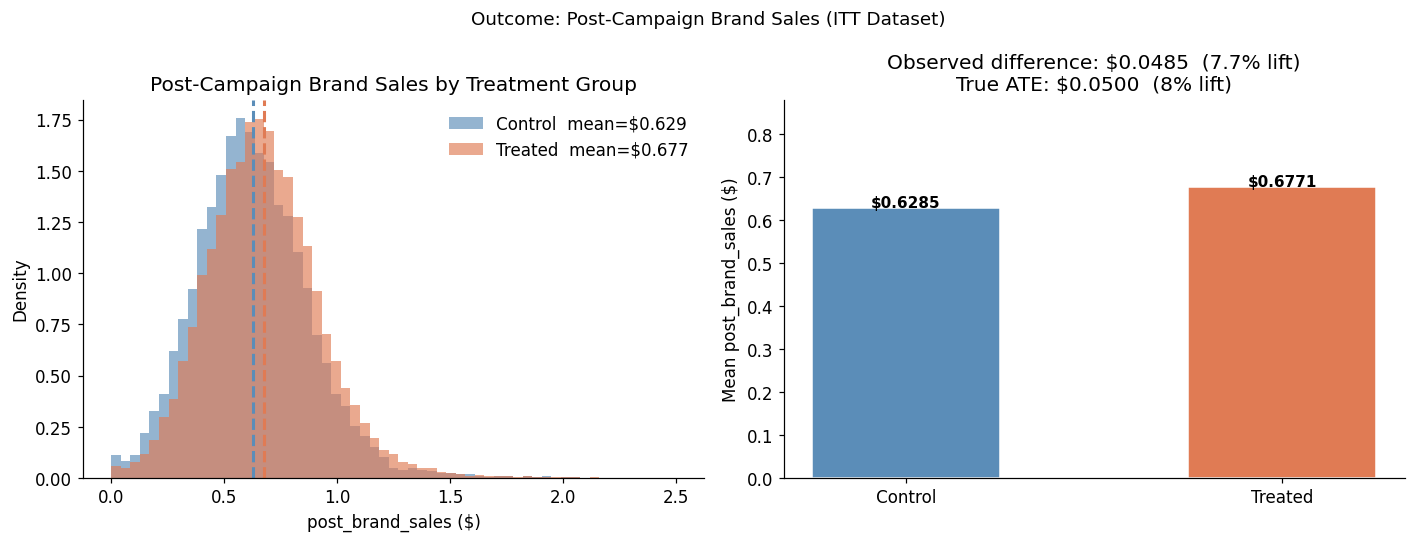

Naive ATE (diff-in-means): $0.0485  (7.7% lift)
True ATE:                  $0.0500  (8% lift)

The ITT estimate is very close to the true effect — as expected with randomization.
Compare this to the observational dataset naive estimate (~$0.11).


In [45]:
# ── Outcome distributions ─────────────────────────────────────────────────────
mean_t = treated['post_brand_sales'].mean()
mean_c = control['post_brand_sales'].mean()
naive_ate = mean_t - mean_c

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bins = np.linspace(0, 2.5, 60)
ax = axes[0]
ax.hist(control['post_brand_sales'], bins=bins, alpha=0.65, color=CONTROL_COLOR,
        label=f'Control  mean=${mean_c:.3f}', density=True)
ax.hist(treated['post_brand_sales'], bins=bins, alpha=0.65, color=TREATED_COLOR,
        label=f'Treated  mean=${mean_t:.3f}', density=True)
ax.axvline(mean_c, color=CONTROL_COLOR, linestyle='--', linewidth=2)
ax.axvline(mean_t, color=TREATED_COLOR, linestyle='--', linewidth=2)
ax.set_xlabel('post_brand_sales ($)')
ax.set_ylabel('Density')
ax.set_title('Post-Campaign Brand Sales by Treatment Group')
ax.legend(frameon=False)

ax2 = axes[1]
ax2.bar(['Control', 'Treated'], [mean_c, mean_t],
        color=[CONTROL_COLOR, TREATED_COLOR], edgecolor='white', width=0.5)
ax2.set_ylabel('Mean post_brand_sales ($)')
ax2.set_title(f'Observed difference: ${naive_ate:.4f}  ({naive_ate/mean_c:.1%} lift)\nTrue ATE: $0.0500  (8% lift)')
ax2.set_ylim(0, mean_t * 1.3)
for i, (lbl, val) in enumerate(zip(['Control', 'Treated'], [mean_c, mean_t])):
    ax2.text(i, val + 0.002, f'${val:.4f}', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Outcome: Post-Campaign Brand Sales (ITT Dataset)', fontsize=12)
plt.tight_layout()
plt.show()

print(f'Naive ATE (diff-in-means): ${naive_ate:.4f}  ({naive_ate/mean_c:.1%} lift)')
print(f'True ATE:                  $0.0500  (8% lift)')
print()
print('The ITT estimate is very close to the true effect — as expected with randomization.')
print('Compare this to the observational dataset naive estimate (~$0.11).')

---
## Step 8: Comparing ITT vs. Observational — The Value of Randomization

**What we are doing:** Load the observational dataset and plot the three key numbers side by side: observational naive ATE, ITT naive ATE, and the true ATE (known because this is synthetic data).

**Why this is the capstone of the EDA:** This comparison makes concrete the entire motivation for causal inference methods. The observational naive estimate looks impressive — high lift, seemingly profitable campaign. But it is more than twice the true effect. Only the randomized design recovers the truth without adjustment.

**What to look for:**
- The three bars: observational bias, randomized truth, and synthetic ground truth
- How different are they? What does the bias imply for business decisions?

**Discussion prompt:** Suppose the firm uses the observational naive estimate (~$0.11) to justify its ad budget. What happens when it scales up spending based on a false premise of 18% lift? What would it discover when it eventually runs the randomized holdout?

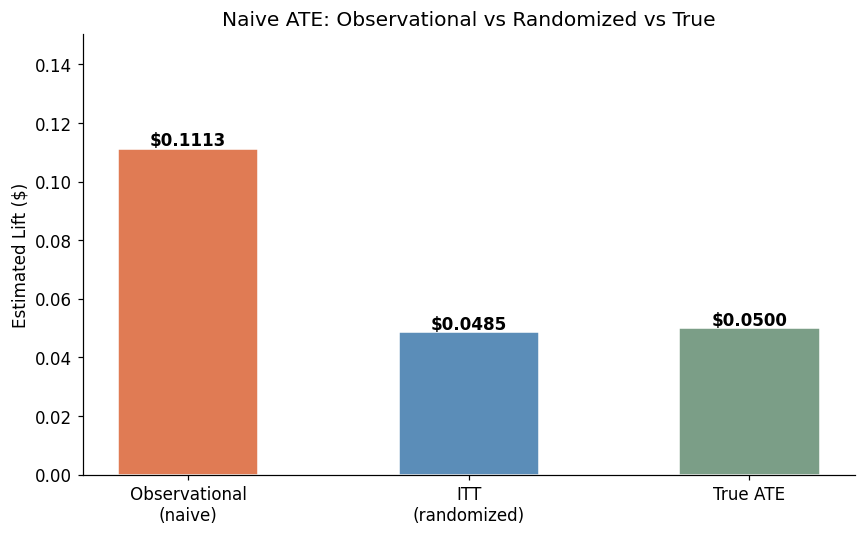

Observational naive ATE:  $0.1113  (biased upward by targeting)
ITT naive ATE:            $0.0485  (close to truth — randomization worked)
True ATE:                 $0.0500

Selection bias in observational data: $0.0613
Residual error in ITT:                $-0.0015  (sampling noise + geographic imbalance)


In [46]:
# ── Side-by-side: naive ATE comparison ───────────────────────────────────────
# Load the observational dataset to compute its naive ATE for comparison
try:
    obs = pd.read_csv('/content/drive/MyDrive/observational_dataset.csv')
except FileNotFoundError:
    try:
        obs = pd.read_csv('/content/drive/MyDrive/UC_CI/data/observational_dataset.csv')
    except FileNotFoundError:
        print("Could not find 'observational_dataset.csv' on your Google Drive.")
        raise

# Compute the observational naive ATE: simple treated - control difference
obs_naive = obs[obs['is_treated']==1]['post_brand_sales'].mean() - \
            obs[obs['is_treated']==0]['post_brand_sales'].mean()

# ── Plot the three estimates ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

estimates = [obs_naive, naive_ate, 0.05]
labels    = ['Observational\n(naive)', 'ITT\n(randomized)', 'True ATE']
colors    = [TREATED_COLOR, CONTROL_COLOR, '#7B9E87']

bars = ax.bar(labels, estimates, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, estimates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'${val:.4f}', ha='center', fontsize=11, fontweight='bold')

ax.set_ylabel('Estimated Lift ($)')
ax.set_title('Naive ATE: Observational vs Randomized vs True')
ax.set_ylim(0, obs_naive * 1.35)
plt.tight_layout()
plt.show()

# ── Print the key comparison numbers ─────────────────────────────────────────
print(f'Observational naive ATE:  ${obs_naive:.4f}  (biased upward by targeting)')
print(f'ITT naive ATE:            ${naive_ate:.4f}  (close to truth — randomization worked)')
print(f'True ATE:                 $0.0500')
print()
print(f'Selection bias in observational data: ${obs_naive - 0.05:.4f}')
print(f'Residual error in ITT:                ${naive_ate - 0.05:.4f}  (sampling noise + geographic imbalance)')

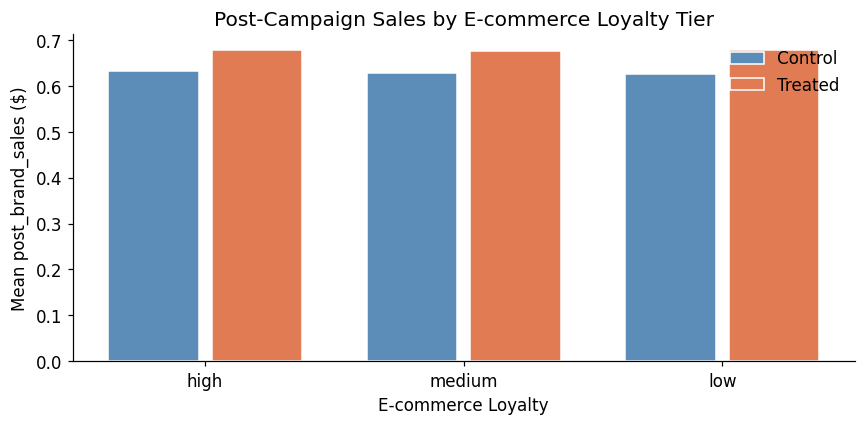

Lift (Treated - Control) by loyalty tier:
ecomm_loyalty  Control  Treated   Lift
         high 0.632297 0.678087 0.0458
       medium 0.628628 0.675661 0.0470
          low 0.625804 0.678650 0.0528


In [47]:
# ── Outcome by ecomm_loyalty ──────────────────────────────────────────────────
loyalty_means = (
    df.groupby(['ecomm_loyalty', 'is_treated'], observed=True)['post_brand_sales']
    .mean()
    .unstack('is_treated')
    .rename(columns={0: 'Control', 1: 'Treated'})
    .reindex(['high','medium','low'])
    .reset_index()
)
loyalty_means['Lift'] = (loyalty_means['Treated'] - loyalty_means['Control']).round(4)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3)
ax.bar(x - 0.2, loyalty_means['Control'], width=0.35, color=CONTROL_COLOR, label='Control', edgecolor='white')
ax.bar(x + 0.2, loyalty_means['Treated'], width=0.35, color=TREATED_COLOR, label='Treated', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(loyalty_means['ecomm_loyalty'])
ax.set_xlabel('E-commerce Loyalty')
ax.set_ylabel('Mean post_brand_sales ($)')
ax.set_title('Post-Campaign Sales by E-commerce Loyalty Tier')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print('Lift (Treated - Control) by loyalty tier:')
print(loyalty_means[['ecomm_loyalty','Control','Treated','Lift']].to_string(index=False))

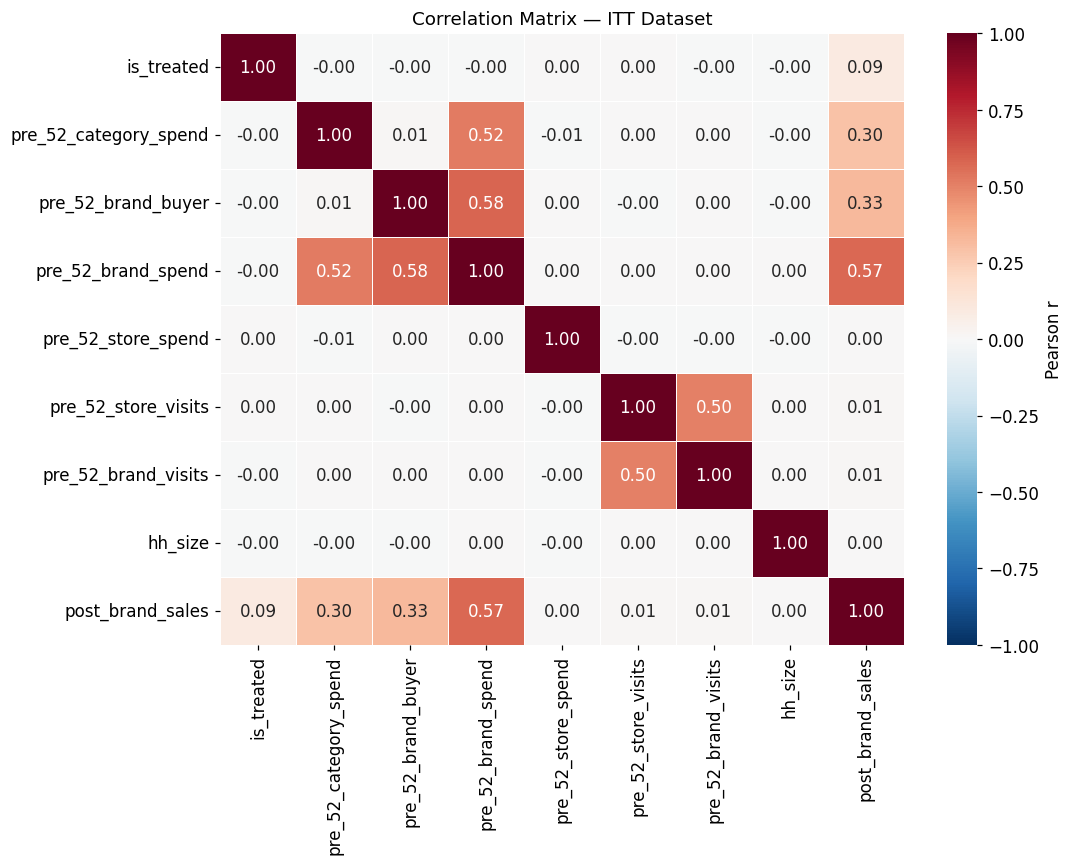

Correlation of is_treated with other variables:
  post_brand_sales                |r| = 0.0862
  pre_52_brand_visits             |r| = 0.0034
  pre_52_store_visits             |r| = 0.0031
  hh_size                         |r| = 0.0030
  pre_52_brand_buyer              |r| = 0.0025
  pre_52_category_spend           |r| = 0.0023
  pre_52_brand_spend              |r| = 0.0021
  pre_52_store_spend              |r| = 0.0004

In a randomized dataset, is_treated should have near-zero correlation with
all pre-treatment variables. Compare this to the observational dataset.


In [48]:
# ── Correlation heatmap ───────────────────────────────────────────────────────
numeric_cols = [
    'is_treated',
    'pre_52_category_spend',
    'pre_52_brand_buyer',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'pre_52_brand_visits',
    'hh_size',
    'post_brand_sales',
]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr, ax=ax, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.5, cbar_kws={'label': 'Pearson r'},
)
ax.set_title('Correlation Matrix — ITT Dataset', fontsize=12)
plt.tight_layout()
plt.show()

print('Correlation of is_treated with other variables:')
treat_corr = corr['is_treated'].drop('is_treated').abs().sort_values(ascending=False)
for col, val in treat_corr.items():
    print(f'  {col:<30}  |r| = {val:.4f}')
print()
print('In a randomized dataset, is_treated should have near-zero correlation with')
print('all pre-treatment variables. Compare this to the observational dataset.')

---
## 7. Comparing ITT vs Observational: The Power of Randomization

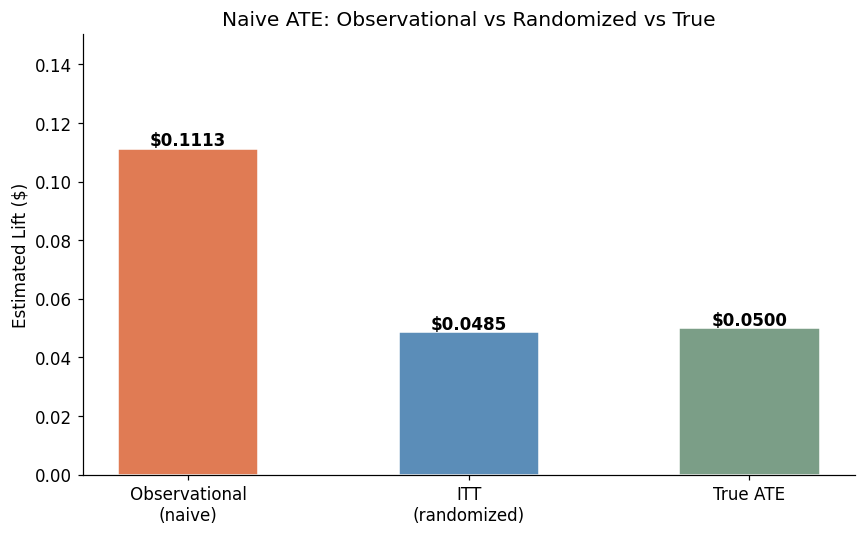

Observational naive ATE:  $0.1113  (biased upward by targeting)
ITT naive ATE:            $0.0485  (close to truth — randomization worked)
True ATE:                 $0.0500

Selection bias in observational data: $0.0613
Residual error in ITT:                $-0.0015  (noise + geographic imbalance)


In [49]:
# ── Side-by-side: naive ATE comparison ───────────────────────────────────────
try:
    obs = pd.read_csv('/content/drive/MyDrive/observational_dataset.csv')
except FileNotFoundError:
    try:
        obs = pd.read_csv('/content/drive/MyDrive/UC_CI/data/observational_dataset.csv')
    except FileNotFoundError:
        print("Could not find 'observational_dataset.csv' on your Google Drive.")
        raise

obs_naive = obs[obs['is_treated']==1]['post_brand_sales'].mean() - \
            obs[obs['is_treated']==0]['post_brand_sales'].mean()

fig, ax = plt.subplots(figsize=(8, 5))

estimates = [obs_naive, naive_ate, 0.05]
labels    = ['Observational\n(naive)', 'ITT\n(randomized)', 'True ATE']
colors    = [TREATED_COLOR, CONTROL_COLOR, '#7B9E87']

bars = ax.bar(labels, estimates, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, estimates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'${val:.4f}', ha='center', fontsize=11, fontweight='bold')

ax.set_ylabel('Estimated Lift ($)')
ax.set_title('Naive ATE: Observational vs Randomized vs True')
ax.set_ylim(0, obs_naive * 1.35)
plt.tight_layout()
plt.show()

print(f'Observational naive ATE:  ${obs_naive:.4f}  (biased upward by targeting)')
print(f'ITT naive ATE:            ${naive_ate:.4f}  (close to truth — randomization worked)')
print(f'True ATE:                 $0.0500')
print()
print(f'Selection bias in observational data: ${obs_naive - 0.05:.4f}')
print(f'Residual error in ITT:                ${naive_ate - 0.05:.4f}  (noise + geographic imbalance)')

---
## Summary

What we learned from this EDA:

1. **Randomization worked** — pre-treatment variables are balanced between treated and control groups. This is in sharp contrast to the observational dataset.
2. **The naive outcome difference (~$0.05) is close to the true ATE ($0.05)** — randomization removed the selection bias.
3. **Division 508 has a slightly elevated treatment rate (~82% vs ~70%)** — a subtle geographic imbalance introduced by imperfect implementation. Worth noting but unlikely to materially change results.
4. **Feature–outcome relationships are symmetric** — both treated and control groups show similar relationships between category spend and sales outcomes, confirming that the groups are comparable.
5. **The correlations between `is_treated` and pre-treatment variables are near zero** — the hallmark of successful randomization.

**Next step:** Run `itt_notebook.ipynb` to formally estimate the ITT treatment effect with confidence intervals, regression adjustment, and subgroup analysis.